<a href="https://colab.research.google.com/github/AK888-hp/ML-II_Lab/blob/main/kmeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import seaborn as sns
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [ ]:
df = sns.load_dataset("penguins")

print("First five rows:")
print(df.head())


First five rows:
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  
0       3750.0    Male  
1       3800.0  Female  
2       3250.0  Female  
3          NaN     NaN  
4       3450.0  Female  


In [ ]:
features = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]
target = "species"

In [ ]:
df = df[features + [target]].dropna()

X = df[features]
y = df[target]


In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(X_scaled)

# 6. Map each cluster to its majority species
cluster_to_species = (
    df.groupby("cluster")[target]
    .agg(lambda values: values.mode().iloc[0])
    .to_dict()
)

df["predicted_species"] = df["cluster"].map(cluster_to_species)

print("\nCluster-to-species mapping:")
print(cluster_to_species)



Cluster-to-species mapping:
{0: 'Chinstrap', 1: 'Gentoo', 2: 'Adelie'}


In [ ]:
print("\nAccuracy:", round(
    accuracy_score(y, df["predicted_species"]) * 100, 2
), "%")

print("\nConfusion Matrix:")
print(confusion_matrix(
    y, df["predicted_species"],
    labels=["Adelie", "Chinstrap", "Gentoo"]
))

print("\nClassification Report:")
print(classification_report(
    y, df["predicted_species"], zero_division=0
))



Accuracy: 91.52 %

Confusion Matrix:
[[127  24   0]
 [  5  63   0]
 [  0   0 123]]

Classification Report:
              precision    recall  f1-score   support

      Adelie       0.96      0.84      0.90       151
   Chinstrap       0.72      0.93      0.81        68
      Gentoo       1.00      1.00      1.00       123

    accuracy                           0.92       342
   macro avg       0.90      0.92      0.90       342
weighted avg       0.93      0.92      0.92       342



In [ ]:
print("\nSample predictions:")
print(df[[target, "cluster", "predicted_species"]].head(10))



Sample predictions:
   species  cluster predicted_species
0   Adelie        2            Adelie
1   Adelie        2            Adelie
2   Adelie        2            Adelie
4   Adelie        2            Adelie
5   Adelie        2            Adelie
6   Adelie        2            Adelie
7   Adelie        2            Adelie
8   Adelie        2            Adelie
9   Adelie        0         Chinstrap
10  Adelie        2            Adelie


In [ ]:
new_penguin = pd.DataFrame([{
    "bill_length_mm": 39.1,
    "bill_depth_mm": 18.7,
    "flipper_length_mm": 181,
    "body_mass_g": 3750
}])

In [ ]:
new_penguin_scaled = scaler.transform(new_penguin)

In [ ]:
new_cluster = kmeans.predict(new_penguin_scaled)[0]

In [ ]:
predicted_species = cluster_to_species[new_cluster]

In [ ]:
print("\n--- NEW PENGUIN CLASSIFICATION ---")
print("Input values:")
print(new_penguin)

print("Predicted cluster:", new_cluster)
print("Predicted species:", predicted_species)


--- NEW PENGUIN CLASSIFICATION ---
Input values:
   bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
0            39.1           18.7                181         3750
Predicted cluster: 2
Predicted species: Adelie


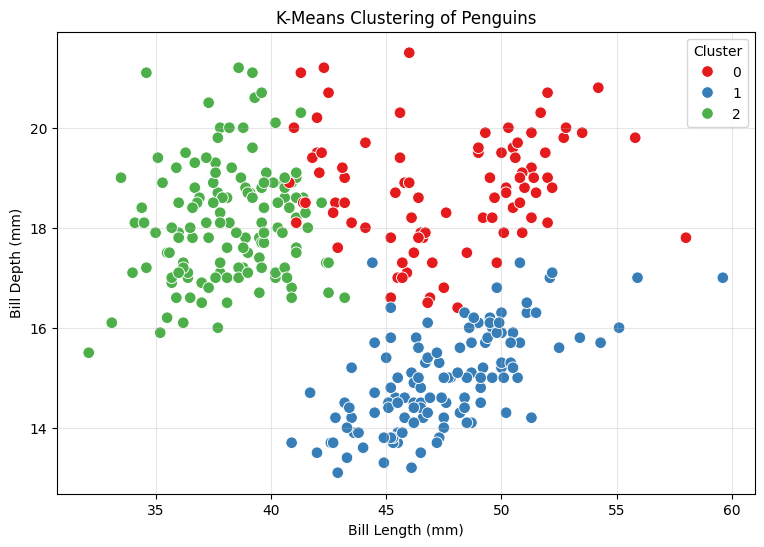

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="bill_length_mm",
    y="bill_depth_mm",
    hue="cluster",
    palette="Set1",
    s=70
)

plt.title("K-Means Clustering of Penguins")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Bill Depth (mm)")
plt.legend(title="Cluster")
plt.grid(alpha=0.3)
plt.show()

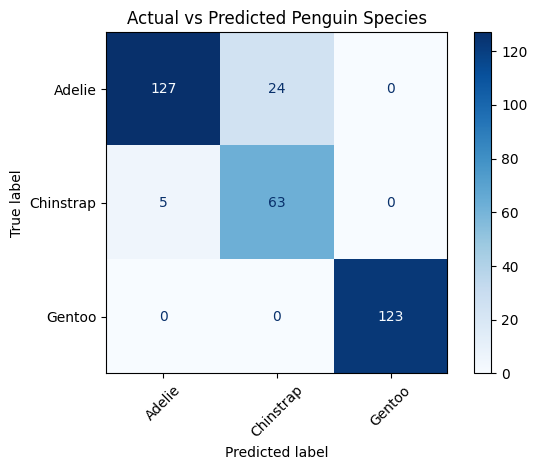

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y,
    df["predicted_species"],
    labels=["Adelie", "Chinstrap", "Gentoo"],
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Actual vs Predicted Penguin Species")
plt.tight_layout()
plt.show()

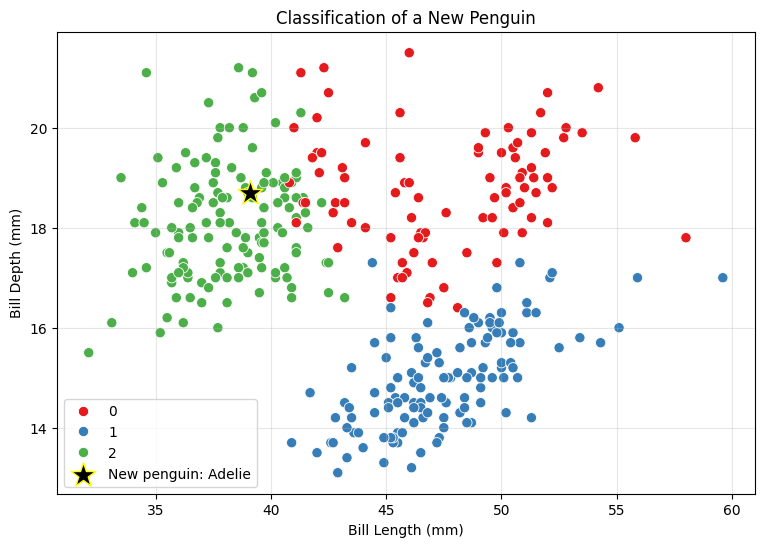

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="bill_length_mm",
    y="bill_depth_mm",
    hue="cluster",
    palette="Set1",
    s=55
)

plt.scatter(
    new_penguin["bill_length_mm"].iloc[0],
    new_penguin["bill_depth_mm"].iloc[0],
    color="black",
    marker="*",
    s=350,
    edgecolor="yellow",
    label=f"New penguin: {predicted_species}"
)

plt.title("Classification of a New Penguin")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Bill Depth (mm)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()